# DSCI 552 HW 5
Caitlyn Chan

In [59]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 552
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 200)

# 1a. load accute inflamations data

In [37]:
diag_cols = ["temperature", "nausea", "lumbar_pain", "urine_pushing",
             "micturition_pains", "burning_urethra",
             "bladder_inflammation", "nephritis"]

def read_diagnosis(path):
    for enc in ("utf-8", "utf-16"):
        try:
            return pd.read_csv(path, sep="\t", header=None, names=diag_cols, decimal=",", encoding=enc)
        except UnicodeError:
            continue

diag = read_diagnosis("diagnosis.data")
for c in diag_cols[1:]:
    diag[c] = diag[c].str.strip().map({"yes": 1, "no": 0})

print(diag.shape)
diag.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,bladder_inflammation,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


## b. build decision tree on data set + plot

Answering footnote 1: I think that the label powerset method is better here. With only 2 labels, there's only 4 combinations, with all of them appearing in the data, and it keeps the relationship between two diseases and gives one tree instead of 2 which makes it easier to interpret.

In [38]:
X_diag = diag.iloc[:, :6]
Y_diag = diag[["bladder_inflammation", "nephritis"]]

# label powerset: 4 classes from the two binary labels
label_map = {(0, 0): "none", (1, 0): "bladder only", (0, 1): "nephritis only", (1, 1): "both"}
y_power = Y_diag.apply(lambda r: label_map[(r.iloc[0], r.iloc[1])], axis=1)
print(y_power.value_counts())

bladder only      40
nephritis only    31
none              30
both              19
Name: count, dtype: int64


depth: 4 leaves: 6 training accuracy: 1.0


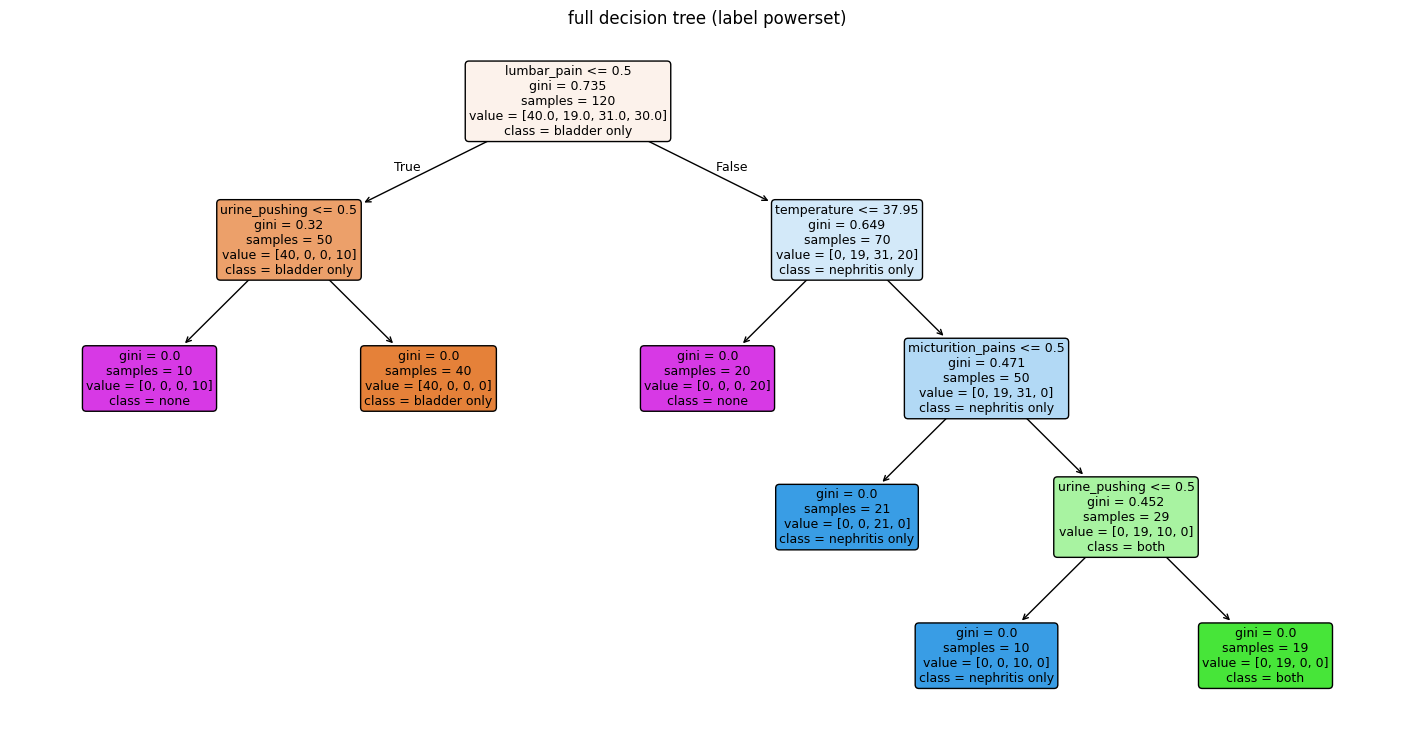

In [39]:
full_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
full_tree.fit(X_diag, y_power)
print("depth:", full_tree.get_depth(), "leaves:", full_tree.get_n_leaves(),
      "training accuracy:", full_tree.score(X_diag, y_power))

plt.figure(figsize=(18, 9))
plot_tree(full_tree, feature_names=X_diag.columns, class_names=full_tree.classes_,
          filled=True, rounded=True, fontsize=9)
plt.title("full decision tree (label powerset)")
plt.show()

## c. convert decision rules into set of if-then rules

In [40]:
binary_features = set(X_diag.columns) - {"temperature"}

def readable(name, op, thr):
    if name in binary_features:
        return f"{name} = {'no' if op == '<=' else 'yes'}"
    return f"{name} {op} {thr:.2f}"

def tree_to_rules(model, feature_names):
    t = model.tree_
    rules = []

    def recurse(node, conditions):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name = feature_names[t.feature[node]]
            thr = t.threshold[node]
            recurse(t.children_left[node],  conditions + [readable(name, "<=", thr)])
            recurse(t.children_right[node], conditions + [readable(name, ">", thr)])
        else:
            counts = t.value[node][0]
            label = model.classes_[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            cond = " AND ".join(conditions) if conditions else "TRUE"
            rules.append(f"IF {cond} THEN {label}   (n={n})")

    recurse(0, [])
    return rules

for i, r in enumerate(tree_to_rules(full_tree, list(X_diag.columns)), 1):
    print(f"Rule {i}: {r}")

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none   (n=10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only   (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only   (n=21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only   (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (n=19)


## d. cost-complexity pruning


,alpha,cv_acc,cv_std,leaves
0,0.000000,0.991667,0.016667,6
1,0.098167,0.858333,0.050000,4
2,0.133333,0.766667,0.062361,3
3,0.182000,0.675000,0.066667,2
4,0.222917,0.483333,0.122474,1


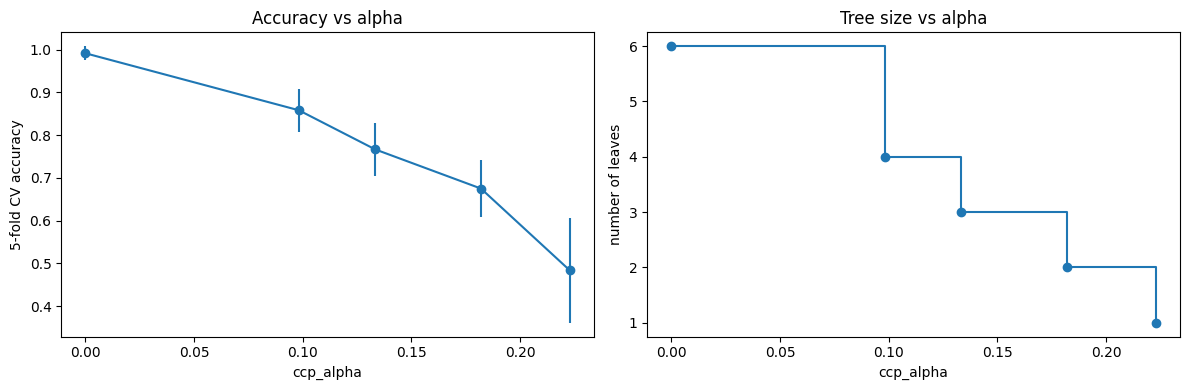

In [41]:
path = full_tree.cost_complexity_pruning_path(X_diag, y_power)
alphas = np.unique(path.ccp_alphas)
alphas = alphas[alphas >= 0]

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    s = cross_val_score(m, X_diag, y_power, cv=skf)
    m.fit(X_diag, y_power)
    rows.append({"alpha": a, "cv_acc": s.mean(), "cv_std": s.std(), "leaves": m.get_n_leaves()})
prune_df = pd.DataFrame(rows)
display(prune_df)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].errorbar(prune_df.alpha, prune_df.cv_acc, yerr=prune_df.cv_std, marker="o")
ax[0].set(xlabel="ccp_alpha", ylabel="5-fold CV accuracy", title="Accuracy vs alpha")
ax[1].step(prune_df.alpha, prune_df.leaves, where="post", marker="o")
ax[1].set(xlabel="ccp_alpha", ylabel="number of leaves", title="Tree size vs alpha")
plt.tight_layout(); plt.show()

chosen alpha = 0.0000  (CV accuracy = 0.992)
leaves: 6 depth: 4 training accuracy: 1.0


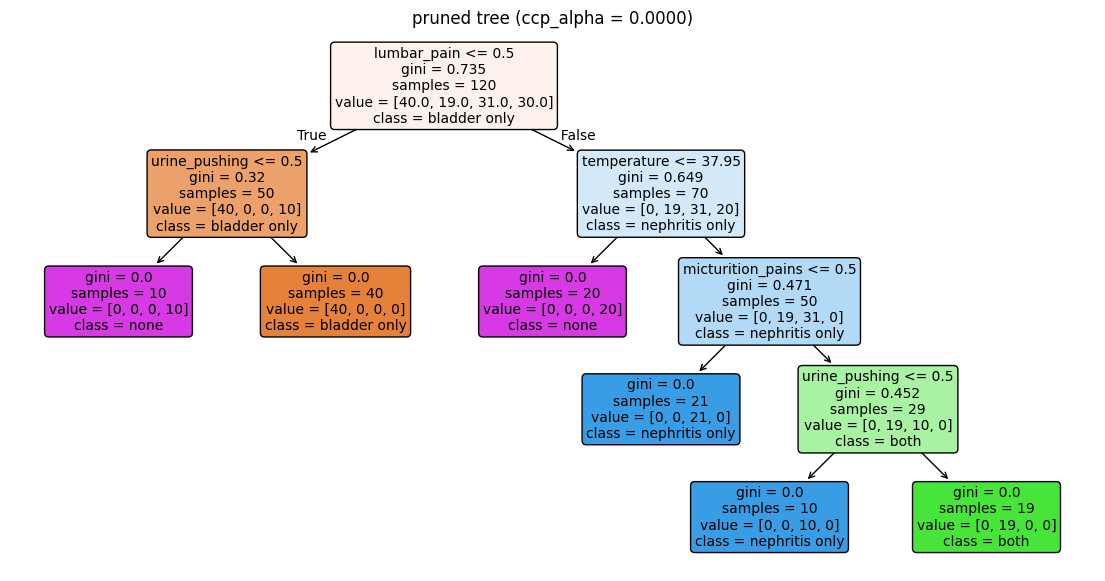

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none   (n=10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only   (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no THEN nephritis only   (n=21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no THEN nephritis only   (n=10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes THEN both   (n=19)


In [42]:
best_acc = prune_df.cv_acc.max()
best_alpha = prune_df.loc[np.isclose(prune_df.cv_acc, best_acc), "alpha"].max()
print(f"chosen alpha = {best_alpha:.4f}  (CV accuracy = {best_acc:.3f})")

pruned_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha).fit(X_diag, y_power)
print("leaves:", pruned_tree.get_n_leaves(), "depth:", pruned_tree.get_depth(),
      "training accuracy:", pruned_tree.score(X_diag, y_power))

plt.figure(figsize=(14, 7))
plot_tree(pruned_tree, feature_names=X_diag.columns, class_names=pruned_tree.classes_,
          filled=True, rounded=True, fontsize=10)
plt.title(f"pruned tree (ccp_alpha = {best_alpha:.4f})")
plt.show()

for i, r in enumerate(tree_to_rules(pruned_tree, list(X_diag.columns)), 1):
    print(f"Rule {i}: {r}")

In [43]:
next_alpha = prune_df.loc[prune_df.alpha > best_alpha, "alpha"].min()
smaller = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=next_alpha).fit(X_diag, y_power)
print(f"alpha = {next_alpha:.4f} | leaves: {smaller.get_n_leaves()} | "
      f"CV accuracy: {prune_df.loc[prune_df.alpha == next_alpha, 'cv_acc'].item():.3f}")
for i, r in enumerate(tree_to_rules(smaller, list(X_diag.columns)), 1):
    print(f"Rule {i}: {r}")

alpha = 0.0982 | leaves: 4 | CV accuracy: 0.858
Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN none   (n=10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN bladder only   (n=40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN none   (n=20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 THEN nephritis only   (n=50)


Pruning picks α = 0, so the unpruned tree (6 leaves, 6 rules) is the minimal tree. Any more pruning drops CV accuracy from roughly 99% to 86%.

# 2. The LASSO and Boosting for Regression

## a. load Communities and Crime data

In [44]:
with open("communities.names") as f:
    crime_cols = re.findall(r"@attribute\s+(\S+)", f.read())
print(len(crime_cols), "columns")

crime = pd.read_csv("communities.data", header=None, names=crime_cols, na_values="?")
print(crime.shape)
crime.head()

128 columns
(1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,...,LemasSwFTFieldOps,LemasSwFTFieldPerPop,LemasTotalReq,LemasTotReqPerPop,PolicReqPerOffic,PolicPerPop,RacialMatchCommPol,PctPolicWhite,PctPolicBlack,PctPolicHisp,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.0,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,...,0.96,0.17,0.06,0.18,0.44,0.13,0.94,0.93,0.03,0.07,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.0,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,0.06,1.0,0.58,0.89,0.21,0.43,0.36,0.20,0.82,0.51,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,0.02,0.9,0.50,0.72,0.16,0.68,0.44,0.11,0.71,0.46,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


## b. missing values and non-predictive features

In [45]:
nonpredictive = ["state", "county", "community", "communityname", "fold"]
crime = crime.drop(columns=nonpredictive)
target = "ViolentCrimesPerPop"
features = [c for c in crime.columns if c != target]
print(len(features), "features")

missing = crime.isna().sum()
missing[missing > 0].sort_values(ascending=False)

122 features


,0
LemasSwornFT,1675
LemasSwFTPerPop,1675
LemasSwFTFieldOps,1675
LemasTotalReq,1675
LemasSwFTFieldPerPop,1675
LemasTotReqPerPop,1675
PolicReqPerOffic,1675
OfficAssgnDrugUnits,1675
PolicPerPop,1675
RacialMatchCommPol,1675


data imputation technique: median imputation fit on the training set only, then applied to test set

In [46]:
train = crime.iloc[:1495].copy()
test = crime.iloc[1495:].copy()

imputer = SimpleImputer(strategy="median")
X_train = pd.DataFrame(imputer.fit_transform(train[features]), columns=features, index=train.index)
X_test = pd.DataFrame(imputer.transform(test[features]), columns=features, index=test.index)
y_train, y_test = train[target], test[target]

print("train:", X_train.shape, "test:", X_test.shape)
print("missing values left:", X_train.isna().sum().sum() + X_test.isna().sum().sum())

train: (1495, 122) test: (499, 122)
missing values left: 0


## c. correlation matrix

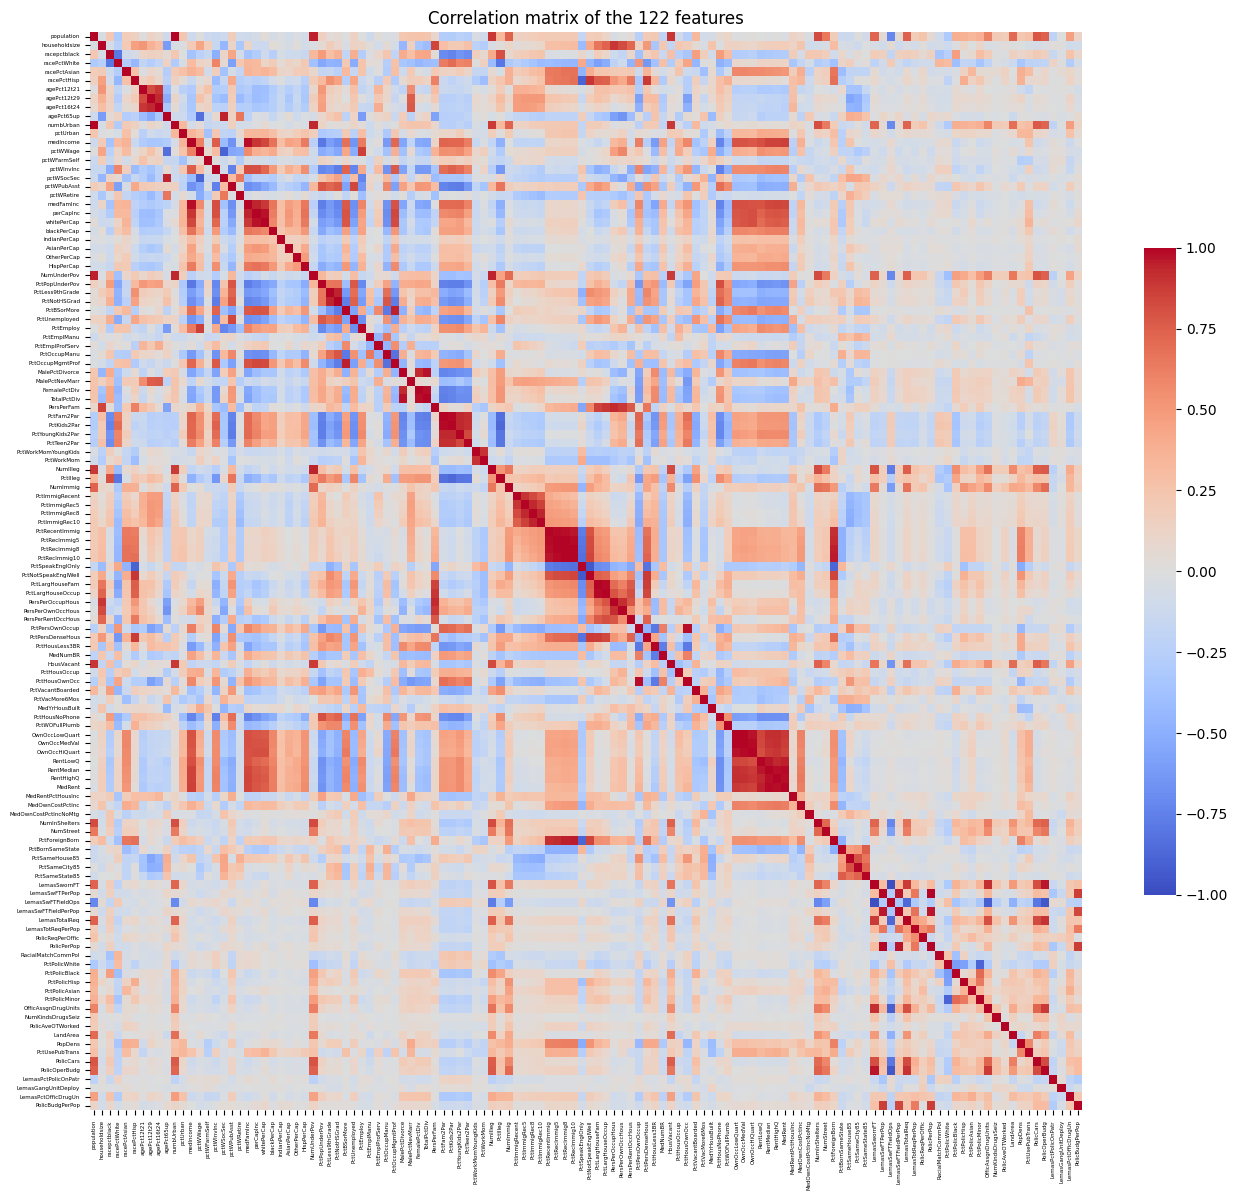

In [47]:
full_imputed = pd.concat([X_train, X_test])
corr = full_imputed.corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"shrink": 0.6})
plt.xticks(fontsize=4); plt.yticks(fontsize=4)
plt.title("Correlation matrix of the 122 features")
plt.show()

## d. calculate coefficient of variation

In [48]:
cv = (full_imputed.std(ddof=1) / full_imputed.mean()).sort_values(ascending=False)
cv_table = cv.rename("CV").to_frame()
cv_table

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
LemasPctOfficDrugUn,2.555266
NumUnderPov,2.304970
population,2.203503
LemasSwornFT,2.080712
numbUrban,2.001744


## e. pick ⌊√128⌋ features by CV

In [49]:
k = int(np.floor(np.sqrt(128)))
top_cv = cv.index[:k].tolist()
print(k, "features:", top_cv)

11 features: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


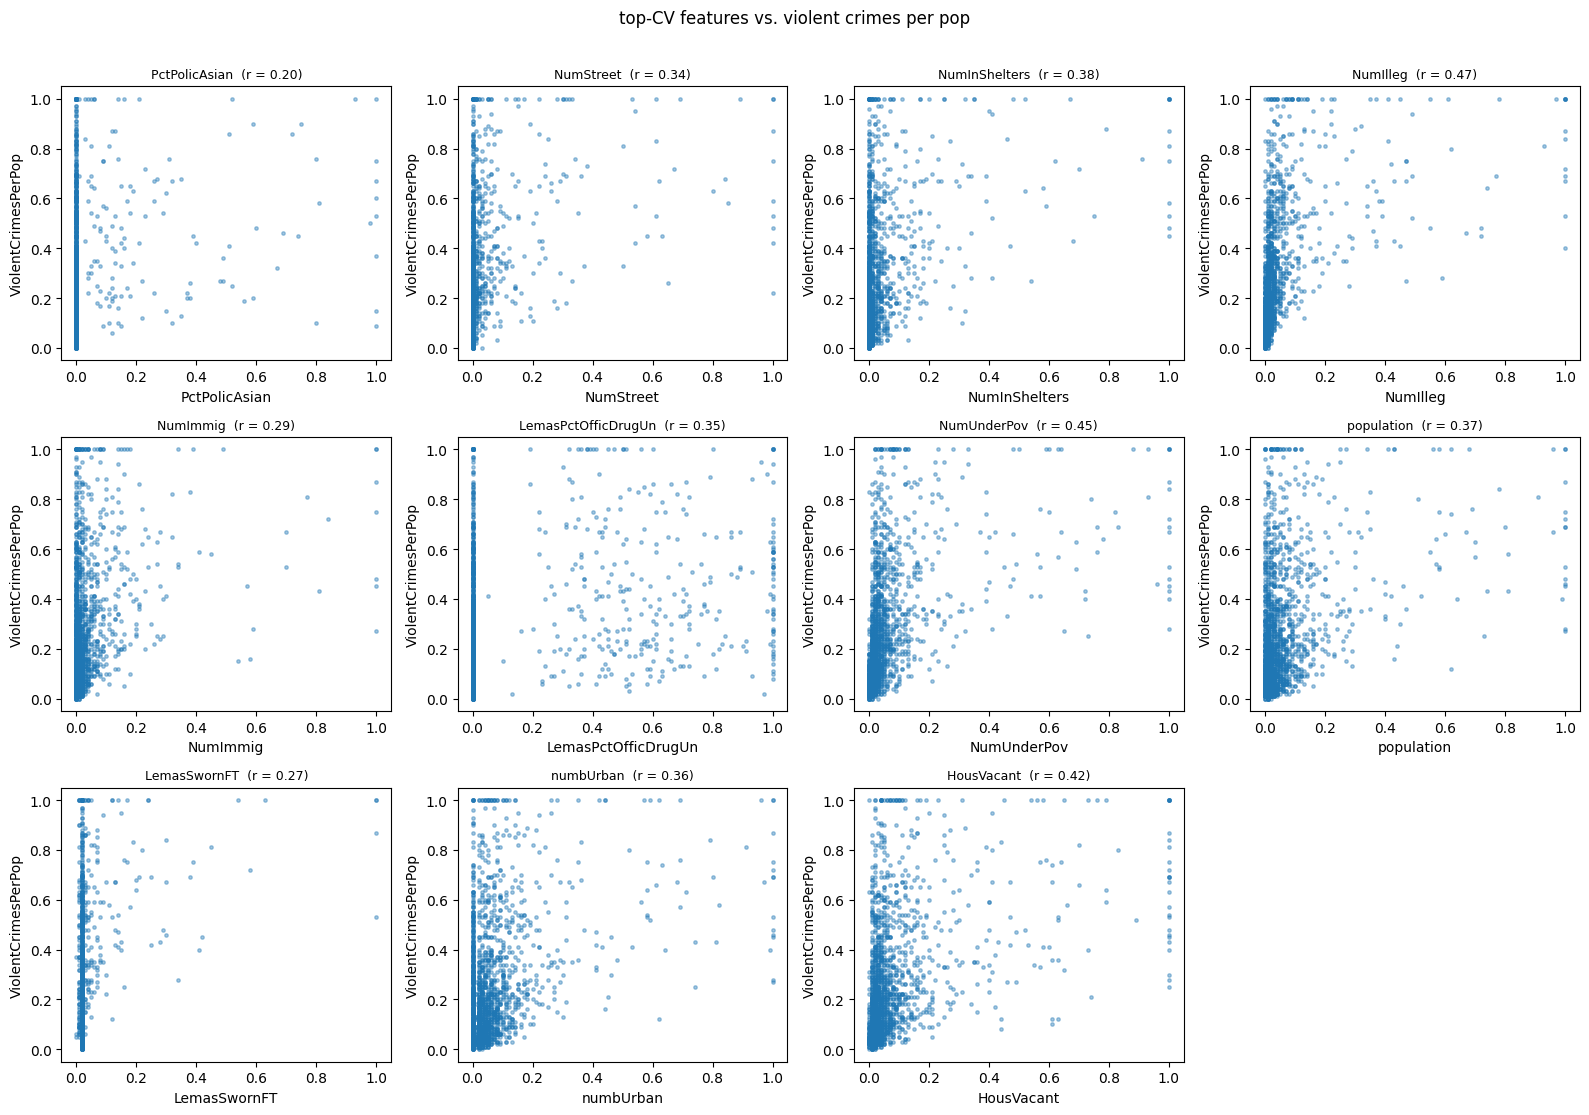

In [50]:
fig, axes = plt.subplots(3, 4, figsize=(16, 11))
for ax, col in zip(axes.flat, top_cv):
    ax.scatter(full_imputed[col], crime[target], s=6, alpha=0.4)
    ax.set(xlabel=col, ylabel=target)
    ax.set_title(f"{col}  (r = {full_imputed[col].corr(crime[target]):.2f})", fontsize=9)
axes.flat[-1].axis("off")
plt.suptitle("top-CV features vs. violent crimes per pop", y=1.01)
plt.tight_layout(); plt.show()

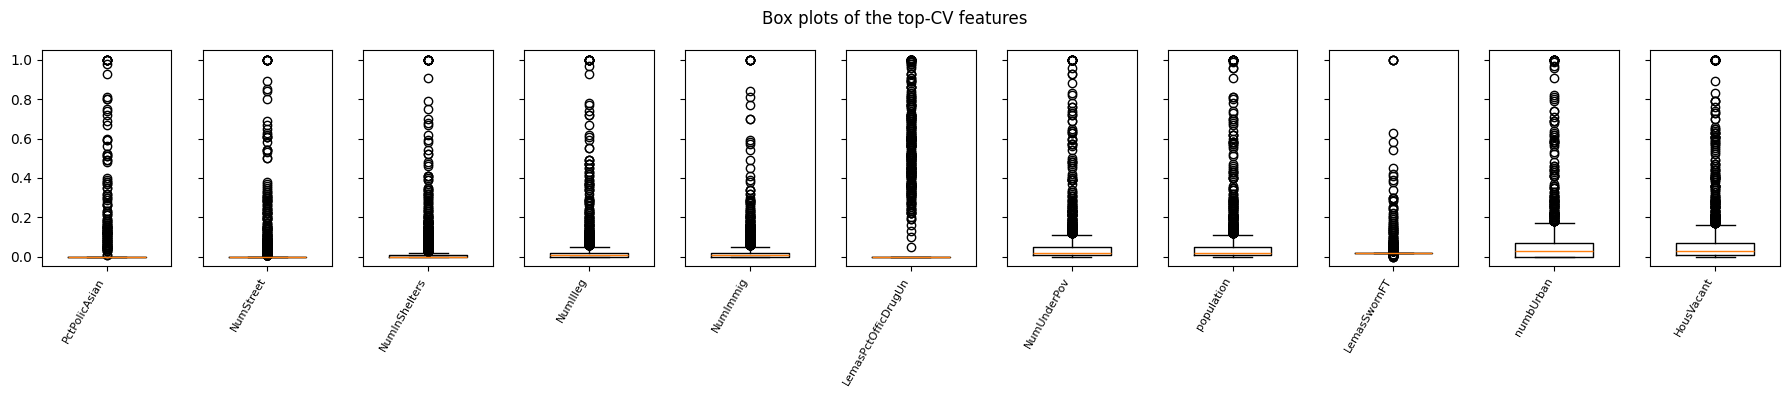

In [51]:
fig, axes = plt.subplots(1, k, figsize=(18, 4), sharey=True)
for ax, col in zip(axes, top_cv):
    ax.boxplot(full_imputed[col], widths=0.6)
    ax.set_xticklabels([col], rotation=60, ha="right", fontsize=8)
plt.suptitle("Box plots of the top-CV features")
plt.tight_layout(); plt.show()

Can you draw conclusions about significance of those features, just by the scatter plots?
- No. The plots hint at direction, but most points pile up near 0, so any trend comes from a few outliers. Each plot also looks at one feature alone, and since the features are highly correlated, significance has to come from a fitted model (ex. p-values, LASSO), not the plots.

## f. linear regression using least squares

In [52]:
results = {}

ols = LinearRegression().fit(X_train, y_train)
results["least squares"] = mean_squared_error(y_test, ols.predict(X_test))
print(f"least squares test MSE: {results['least squares']:.5f}")

least squares test MSE: 0.01797


## g. ridge regression chosen by cross-validation


In [53]:
kf = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
ridge_grid = np.logspace(-4, 4, 200)

ridge = RidgeCV(alphas=ridge_grid, cv=kf, scoring="neg_mean_squared_error").fit(X_train, y_train)
results["ridge"] = mean_squared_error(y_test, ridge.predict(X_test))
print(f"best lambda: {ridge.alpha_:.4f}")
print(f"ridge test MSE: {results['ridge']:.5f}")

best lambda: 2.1964
ridge test MSE: 0.01752


## h. lasso chosen by cross-validation

In [54]:
lasso = LassoCV(alphas=np.logspace(-6, 0, 200), cv=kf, max_iter=50000, random_state=RANDOM_STATE).fit(X_train, y_train)
results["LASSO"] = mean_squared_error(y_test, lasso.predict(X_test))

lasso_selected = pd.Series(lasso.coef_, index=features)
lasso_selected = lasso_selected[lasso_selected != 0].sort_values(key=abs, ascending=False)

print(f"best lambda: {lasso.alpha_:.6f}")
print(f"LASSO test MSE: {results['LASSO']:.5f}")
print(f"{len(lasso_selected)} of {len(features)} variables selected:")
lasso_selected.rename("coefficient").to_frame()

best lambda: 0.000085
LASSO test MSE: 0.01768
79 of 122 variables selected:


,coefficient
agePct12t29,-0.314962
racepctblack,0.269588
PctPersDenseHous,0.236065
PctKids2Par,-0.201221
MedRent,0.181972
PctEmploy,0.171776
RentLowQ,-0.170403
MalePctNevMarr,0.168557
NumStreet,0.163183
PctPopUnderPov,-0.158467


In [55]:
lasso_std = Pipeline([
    ("scale", StandardScaler()),
    ("lasso", LassoCV(alphas=np.logspace(-6, 0, 200), cv=kf, max_iter=50000, random_state=RANDOM_STATE)),
]).fit(X_train, y_train)
results["LASSO (standardized)"] = mean_squared_error(y_test, lasso_std.predict(X_test))

std_model = lasso_std.named_steps["lasso"]
lasso_std_selected = pd.Series(std_model.coef_, index=features)
lasso_std_selected = lasso_std_selected[lasso_std_selected != 0].sort_values(key=abs, ascending=False)

print(f"best lambda: {std_model.alpha_:.6f}")
print(f"LASSO (standardized) test MSE: {results['LASSO (standardized)']:.5f}")
print(f"{len(lasso_std_selected)} of {len(features)} variables selected:")
lasso_std_selected.rename("coefficient").to_frame()

best lambda: 0.000637
LASSO (standardized) test MSE: 0.01772
76 of 122 variables selected:


,coefficient
racepctblack,0.068019
PctPersDenseHous,0.043228
agePct12t29,-0.043049
PctKids2Par,-0.040648
RentLowQ,-0.030677
MedRent,0.030296
PctPopUnderPov,-0.029282
PctEmploy,0.025003
MalePctNevMarr,0.024546
PctIlleg,0.023965


Comparing test errors: test MSE is almost the same: 0.01768 (original) vs 0.01772 (standardized). The model keeps 79 variables before standardizing and 76 after. Standardizing changes the coefficient sizes and the best λ, but barely changes the fit, because the features were already normalized to the scale [0, 1].

## i. fit PCR model on training set

best M: 97
PCR test MSE: 0.01837


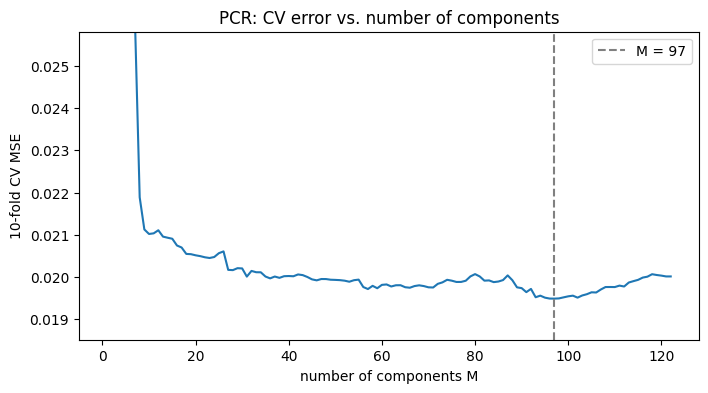

In [56]:
pcr = Pipeline([
    ("scale", StandardScaler()),
    ("pca", PCA(random_state=RANDOM_STATE)),
    ("ols", LinearRegression()),
])
pcr_search = GridSearchCV(pcr, {"pca__n_components": range(1, len(features) + 1)},
                          cv=kf, scoring="neg_mean_squared_error", n_jobs=-1).fit(X_train, y_train)

best_M = pcr_search.best_params_["pca__n_components"]
results["PCR"] = mean_squared_error(y_test, pcr_search.predict(X_test))
print(f"best M: {best_M}")
print(f"PCR test MSE: {results['PCR']:.5f}")

cv_mse = -pcr_search.cv_results_["mean_test_score"]
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(features) + 1), cv_mse)
plt.axvline(best_M, ls="--", c="gray", label=f"M = {best_M}")
plt.ylim(cv_mse.min() * 0.95, np.percentile(cv_mse, 95))
plt.xlabel("number of components M"); plt.ylabel("10-fold CV MSE"); plt.legend()
plt.title("PCR: CV error vs. number of components")
plt.show()

## j. l1-penalized gradient boosting with XGBoost

α = XGBoost’s reg_alpha (L1 penalty), chosen by 10-fold CV

In [57]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                   subsample=0.8, colsample_bytree=0.8,
                   objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=1)

alpha_grid = {"reg_alpha": [0, 1e-4, 1e-3, 1e-2, 0.03, 0.1, 0.3, 1, 3, 10]}
xgb_search = GridSearchCV(xgb, alpha_grid, cv=kf, scoring="neg_mean_squared_error", n_jobs=-1)
xgb_search.fit(X_train, y_train)

best_reg_alpha = xgb_search.best_params_["reg_alpha"]
results["XGBoost (L1)"] = mean_squared_error(y_test, xgb_search.predict(X_test))
print(f"best alpha: {best_reg_alpha}")
print(f"XGBoost test MSE: {results['XGBoost (L1)']:.5f}")

xgb_cv = pd.DataFrame({"reg_alpha": alpha_grid["reg_alpha"],
                       "cv_mse": -xgb_search.cv_results_["mean_test_score"]})
display(xgb_cv)

best alpha: 3
XGBoost test MSE: 0.01607


,reg_alpha,cv_mse
0,0.0000,0.019501
1,0.0001,0.019534
2,0.0010,0.019479
3,0.0100,0.019463
4,0.0300,0.019246
5,0.1000,0.019237
6,0.3000,0.019423
7,1.0000,0.019092
8,3.0000,0.018927
9,10.0000,0.020770


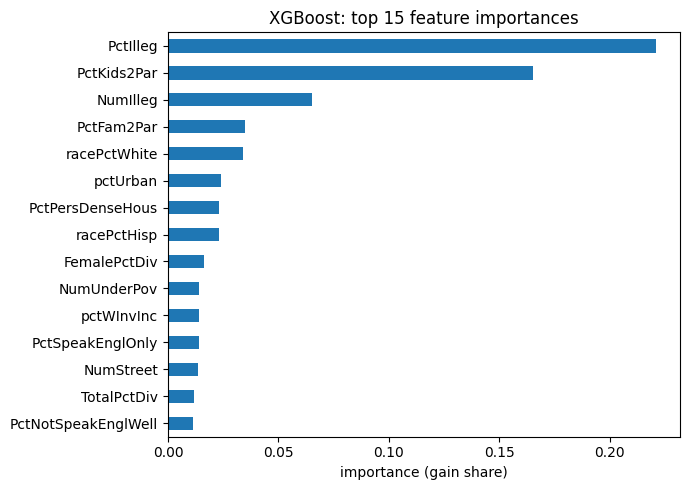

In [58]:
imp = pd.Series(xgb_search.best_estimator_.feature_importances_, index=features)
imp.sort_values(ascending=False).head(15).iloc[::-1].plot.barh(figsize=(7, 5))
plt.title("XGBoost: top 15 feature importances"); plt.xlabel("importance (gain share)")
plt.tight_layout(); plt.show()